In [47]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
smart = pd.read_csv('smart.csv')
smart.drop('Building_ID', axis=1, inplace=True)

missed = smart.isnull().sum()

for col, total in zip(missed.index, missed.values):
    if total > 0 and smart[col].dtype == 'str':        
        smart[col] = smart[col].fillna(smart[col].mode()[0])
    elif total > 0 and smart[col].dtype != 'str':       
        smart[col] = smart[col].fillna(smart[col].median())
    else:
        continue

smart = pd.get_dummies(data=smart, columns=['Building_Type', 'HVAC_Mode'], drop_first=True, dtype=int)
smart.head()

,System_Age_Years,Outdoor_Temperature_C,Indoor_Temperature_C,Airflow_m3_h,Filter_Pressure_Drop_Pa,Compressor_Current_A,Vibration_mm_s,Operating_Hours,Days_Since_Maintenance,Occupancy,Indoor_Humidity_Percent,HVAC_Failure_Next_48h,Building_Type_Hotel,Building_Type_Office,Building_Type_University,HVAC_Mode_Heating,HVAC_Mode_Ventilation
0,17.0,36.3,21.8,1055.3,130.3,12.05,4.97,15957.0,309.0,209.0,80.5,1,0,0,0,1,0
1,17.0,9.8,17.1,331.3,110.1,11.50,1.35,15479.0,83.0,205.0,33.9,0,0,0,0,0,1
2,17.0,19.4,27.0,301.9,205.9,19.47,3.69,24045.0,182.0,23.0,76.6,1,0,0,0,0,1
3,23.0,16.4,20.6,515.7,227.8,19.99,4.47,7739.0,103.0,192.0,58.5,0,1,0,0,0,1
4,23.0,2.7,23.3,964.4,144.0,16.35,4.17,8863.0,373.0,156.0,33.0,0,1,0,0,0,1


In [48]:

y = smart['HVAC_Failure_Next_48h'].values
X = smart.drop("HVAC_Failure_Next_48h", axis=1).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train, y_train)  
print(model.score(X_test, y_test))

print(model.score(X_test, y_test))

0.8403361344537815
0.8403361344537815


In [49]:
smart['HVAC_Failure_Next_48h'].value_counts()

HVAC_Failure_Next_48h
1    296
0    296
Name: count, dtype: int64

In [50]:
from sklearn.metrics import roc_curve, classification_report, confusion_matrix

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.76      0.83        63
           1       0.78      0.93      0.85        56

    accuracy                           0.84       119
   macro avg       0.85      0.85      0.84       119
weighted avg       0.85      0.84      0.84       119

[[48 15]
 [ 4 52]]


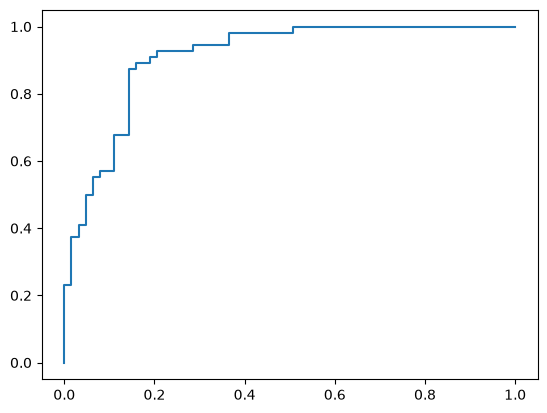

In [53]:
import matplotlib.pyplot as plt
positive_probability = model.predict_proba(X_test)[:,1]
#[:,1] denotes the second column of the matrix, first one one is for 
#negative class, second is for positive class

fpr, tpr, thresholds = roc_curve(y_test,positive_probability)
plt.plot(fpr,tpr)